# Capítulo 3 · Actividad: análisis de datos con NumPy, pandas y matplotlib

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_03/01_actividad_numpy_pandas.ipynb)

En esta actividad haces de **analista de datos**: vas a responder preguntas sobre datos reales con **NumPy** y **pandas**, y después los visualizarás con **matplotlib** y **seaborn**. Lo importante no es solo que el código funcione, sino que **sepas interpretar los resultados**.

### Antes de empezar

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia. Si editas el original tendrás conflictos al sincronizar tu fork.
2. Si todavía no tienes los datos, descárgalos desde la raíz del repo:
   ```bash
   uv run python scripts/download_data.py
   ```
3. Ten a mano las notebooks de clase de `notebooks/lectures/chapter_03/`: `01_numpy`, `02_pandas` y `03_matplotlib`.

### Cómo trabajar

- Cada ejercicio tiene una celda `# Tu código aquí`. Puedes añadir todas las celdas que necesites.
- En las celdas ✍️ responde con tus palabras y **apoya tus respuestas con números** de tus resultados.
- En las partes 1 y 2, las 💡 **pistas** te recuerdan funciones. Si una función no salió en clase, la pista explica cómo usarla. La parte 3 no tiene pistas.
- Al terminar, ejecuta **Kernel → Restart & Run All** y comprueba que todo funciona de arriba abajo.

| Parte | Datos | Herramienta |
|---|---|---|
| 1. La cafetería | ventas de un mes (generadas en la notebook) | NumPy |
| 2. Las propinas | `data/tips.csv` | pandas (+ un poco de NumPy) |
| 3. Visualización | cafetería, propinas y `data/penguins.csv` | matplotlib y seaborn |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"
print("Carpeta de datos:", DATA_DIR)

Carpeta de datos: /Users/pimienta/Library/Mobile Documents/com~apple~CloudDocs/Academic/Samsung Innovation Campus/Course Repo/data


---
## Parte 1 · La cafetería ☕ (NumPy)

Una cafetería vende 5 productos y ha registrado cuántas unidades vendió de cada uno durante **4 semanas** (28 días, de lunes a domingo). La dueña quiere saber cuánto gana, qué días van mejor y qué producto le conviene más.

Ejecuta la siguiente celda para generar los datos. **No hace falta que la modifiques ni que entiendas cada línea.**

In [2]:
# Datos de la cafetería (no hace falta modificar esta celda)
rng = np.random.default_rng(42)

productos = np.array(["café", "latte", "té", "croissant", "sándwich"])
precios = np.array([1.5, 2.8, 1.2, 2.0, 4.5])       # precio de cada producto, en $

# Unidades vendidas cada día: los fines de semana se vende un 50% más
dia_semana = np.tile(np.arange(7), 4)                # 0 = lunes, ..., 6 = domingo
factor = np.where(dia_semana >= 5, 1.5, 1.0)
promedio = np.outer(factor, [30, 22, 12, 18, 9])     # ventas esperadas por día y producto
ventas_planas = rng.poisson(promedio).ravel()         # ¡todo en una sola fila!

print(ventas_planas[:10], "...")
print("Número de valores:", ventas_planas.size)

[35 28  7 16 13 29 16 10 18 11] ...
Número de valores: 140


### Ejercicio 1 · Dar forma a los datos

`ventas_planas` tiene 140 números seguidos: primero las ventas de los 5 productos del día 1, después las del día 2, y así sucesivamente.

a) Crea una matriz `ventas` con forma `(28, 5)`: una **fila por día** y una **columna por producto** (en el mismo orden que `productos`).

b) Imprime su `shape`, `ndim`, `size` y `dtype`.

c) ¿Cuántos cafés se vendieron el primer día? Comprueba que coincide con `ventas_planas[0]`.

> 💡 **Pista:** `reshape`.

In [3]:
ventas = ventas_planas.reshape(28, 5)
print("shape:", ventas.shape)
print("ndim:", ventas.ndim)
print("size:", ventas.size)
print("dtype:", ventas.dtype)
print("Primer día:")
print(ventas[0])
print("Café del primer día:", ventas[0, 0])
print("Coincide con ventas_planas[0]:", ventas[0, 0] == ventas_planas[0])


shape: (28, 5)
ndim: 2
size: 140
dtype: int64
Primer día:
[35 28  7 16 13]
Café del primer día: 35
Coincide con ventas_planas[0]: True


### Ejercicio 2 · Indexación

Obtén, usando índices y *slicing* sobre `ventas`:

a) Las ventas de todos los productos el **primer día**.

b) Las ventas de **latte** (columna 1) durante todo el mes.

c) Las ventas de la **última semana** (los últimos 7 días). Comprueba que su forma es `(7, 5)`.

d) Las ventas de **croissant y sándwich** (las dos últimas columnas) durante la **primera semana**.

> 💡 **Pista:** `M[filas, columnas]`. Recuerda que los índices negativos cuentan desde el final.

In [4]:
# a) Ventas del primer día
primer_dia = ventas[0]
print("Ventas del primer día:", primer_dia)

# b) Ventas de latte durante todo el mes
latte = ventas[:, 1]
print("Ventas de latte:", latte)

# c) Última semana
ultima_semana = ventas[-7:]
print("Última semana:", ultima_semana.shape)
print(ultima_semana)

# d) Croissant y sándwich durante la primera semana
croissant_sandwich = ventas[:7, -2:]
print("Croissant + sándwich (primera semana):", croissant_sandwich.shape)
print(croissant_sandwich)


Ventas del primer día: [35 28  7 16 13]
Ventas de latte: [28 16 17 21 17 29 37 16 23 25 22 19 29 39 24 19 18 22 30 44 27 14 31 21
 30 26 32 45]
Última semana: (7, 5)
[[22 14 11 20  9]
 [34 31 12 27  7]
 [26 21 17 23  7]
 [35 30  3  9 10]
 [23 26 16 21  8]
 [38 32 20 21 11]
 [49 45 18 27  9]]
Croissant + sándwich (primera semana): (7, 2)
[[16 13]
 [18 11]
 [17 10]
 [15  8]
 [17  8]
 [22 14]
 [29 12]]


### Ejercicio 3 · Ingresos

a) Calcula la matriz `ingresos` (forma `(28, 5)`): lo que se ingresó por cada producto cada día.

b) ¿Cuánto ingresó la cafetería en todo el mes?

c) Crea `ingreso_diario`, un array con el ingreso total de **cada día** (forma `(28,)`).

d) ¿Cuál fue el ingreso diario medio, el máximo y el mínimo?

> 💡 **Pistas:**
> - `ventas * precios` multiplica **cada fila** de `ventas` por el vector `precios`, elemento a elemento: la columna del café por 1.5, la del latte por 2.8… (este mecanismo se llama *broadcasting*).
> - `M.sum()` suma todo. `M.sum(axis=1)` suma **cada fila** y devuelve un resultado por fila; `M.sum(axis=0)` suma **cada columna**.

In [5]:
ingresos = ventas * precios
print("Matriz de ingresos:")
print(ingresos)

ingreso_total = ingresos.sum()
print("Ingreso total del mes:", ingreso_total)

ingreso_diario = ingresos.sum(axis=1)
print("Ingreso diario:", ingreso_diario)

print("Ingreso diario medio:", ingreso_diario.mean())
print("Ingreso diario máximo:", ingreso_diario.max())
print("Ingreso diario mínimo:", ingreso_diario.min())


Matriz de ingresos:
[[ 52.5  78.4   8.4  32.   58.5]
 [ 43.5  44.8  12.   36.   49.5]
 [ 49.5  47.6  18.   34.   45. ]
 [ 43.5  58.8  10.8  30.   36. ]
 [ 51.   47.6   9.6  34.   36. ]
 [ 73.5  81.2  30.   44.   63. ]
 [ 79.5 103.6  24.   58.   54. ]
 [ 45.   44.8  15.6  52.   31.5]
 [ 45.   64.4  10.8  36.   27. ]
 [ 39.   70.   10.8  38.   40.5]
 [ 57.   61.6  18.   32.   36. ]
 [ 55.5  53.2   9.6  28.   45. ]
 [ 85.5  81.2  24.   40.   90. ]
 [ 66.  109.2  16.8  58.   67.5]
 [ 42.   67.2  13.2  28.   31.5]
 [ 58.5  53.2   8.4  18.   36. ]
 [ 36.   50.4  13.2  32.   45. ]
 [ 52.5  61.6  19.2  32.   31.5]
 [ 42.   84.   12.   46.   45. ]
 [ 75.  123.2  33.6  56.   49.5]
 [ 51.   75.6  22.8  54.   76.5]
 [ 33.   39.2  13.2  40.   40.5]
 [ 51.   86.8  14.4  54.   31.5]
 [ 39.   58.8  20.4  46.   31.5]
 [ 52.5  84.    3.6  18.   45. ]
 [ 34.5  72.8  19.2  42.   36. ]
 [ 57.   89.6  24.   42.   49.5]
 [ 73.5 126.   21.6  54.   40.5]]
Ingreso total del mes: 6342.5
Ingreso diario: [229.8 18

### Ejercicio 4 · Días buenos y días flojos

Usa este array con el número de cada día (del 1 al 28):
```python
dias = np.arange(1, 29)
```

a) Crea una máscara con los días cuyo ingreso supera el **ingreso diario medio** y muestra **qué días** fueron.

b) ¿**Cuántos** días fueron?

c) Crea un array que diga `"bueno"` o `"flojo"` para cada día, según si supera o no la media.

d) Calcula `dias[mascara] % 7` (el resto de dividir entre 7). El día 1 fue lunes, así que un resto de **6** es sábado y un resto de **0** es domingo. ¿Qué tienen en común los días buenos?

> 💡 **Pistas:** `.sum()` sobre una máscara cuenta los `True`, porque `True` vale 1 y `False` vale 0. Para c), `np.where`.

In [6]:
dias = np.arange(1, 29)
ingreso_diario = (ventas * precios).sum(axis=1)
media_diaria = ingreso_diario.mean()
mascara = ingreso_diario > media_diaria

print("Días por encima de la media:", dias[mascara])
print("Número de días buenos:", mascara.sum())

estado = np.where(mascara, "bueno", "flojo")
print("Estado por día:", estado)

restos = dias[mascara] % 7
print("Resto de días buenos:", restos)
print("Los días buenos tienen resto 1, 6, 0, 6, 0, 5, 6, 0, 2, 6, 0")


Días por encima de la media: [ 1  6  7 13 14 19 20 21 23 27 28]
Número de días buenos: 11
Estado por día: ['bueno' 'flojo' 'flojo' 'flojo' 'flojo' 'bueno' 'bueno' 'flojo' 'flojo'
 'flojo' 'flojo' 'flojo' 'bueno' 'bueno' 'flojo' 'flojo' 'flojo' 'flojo'
 'bueno' 'bueno' 'bueno' 'flojo' 'bueno' 'flojo' 'flojo' 'flojo' 'bueno'
 'bueno']
Resto de días buenos: [1 6 0 6 0 5 6 0 2 6 0]
Los días buenos tienen resto 1, 6, 0, 6, 0, 5, 6, 0, 2, 6, 0


✍️ **Tu respuesta:** 

### Ejercicio 5 · Análisis por semanas

a) Reorganiza `ingreso_diario` en una matriz `por_semana` de forma `(4, 7)`: una fila por semana y una columna por día (lunes a domingo).

b) ¿Cuánto se ingresó **cada semana**?

c) ¿Cuál es el ingreso medio de **cada día de la semana**? ¿Qué día se vende más? Usa:
```python
nombres_dias = np.array(["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"])
```

d) Compara el ingreso medio de un día de **fin de semana** con el de un día **entre semana**. ¿Cuántas veces más se ingresa en fin de semana?

> 💡 **Pistas:** `axis=1` da un resultado por fila (por semana) y `axis=0` uno por columna (por día de la semana). `arr.argmax()` devuelve la **posición** del valor máximo; úsala como índice en `nombres_dias`.

In [7]:
ingreso_diario = (ventas * precios).sum(axis=1)
por_semana = ingreso_diario.reshape(4, 7)
print("Forma de por_semana:", por_semana.shape)
print(por_semana)

print("Ingreso por semana:", por_semana.sum(axis=1))

nombres_dias = np.array(["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"])
ingreso_por_dia = por_semana.mean(axis=0)
print("Ingreso medio por día de la semana:")
for dia, ingreso in zip(nombres_dias, ingreso_por_dia):
    print(f"{dia}: {ingreso:.2f}")
print("Día con mayor ingreso medio:", nombres_dias[ingreso_por_dia.argmax()])

ingreso_semana = por_semana[:, :5].mean()
ingreso_fin_de_semana = por_semana[:, 5:].mean()
print("Ingreso medio entre semana:", ingreso_semana)
print("Ingreso medio fin de semana:", ingreso_fin_de_semana)


Forma de por_semana: (4, 7)
[[229.8 185.8 194.1 179.1 178.2 291.7 319.1]
 [188.9 183.2 198.3 204.6 191.3 320.7 317.5]
 [181.9 174.1 176.6 196.8 229.  337.3 279.9]
 [165.9 237.7 195.7 203.1 204.5 262.1 315.6]]
Ingreso por semana: [1577.8 1604.5 1575.6 1584.6]
Ingreso medio por día de la semana:
lunes: 191.62
martes: 195.20
miércoles: 191.18
jueves: 195.90
viernes: 200.75
sábado: 302.95
domingo: 308.02
Día con mayor ingreso medio: domingo
Ingreso medio entre semana: 194.93
Ingreso medio fin de semana: 305.4875


### Ejercicio 6 · El producto estrella

a) Calcula el ingreso total de **cada producto** en el mes.

b) ¿Qué **porcentaje** del ingreso total aporta cada producto? Redondea a 1 decimal.

c) ¿Qué producto genera **más dinero**? ¿Y cuál vende **más unidades**?

> 💡 **Pista:** `axis=0` y `argmax`, igual que en el ejercicio anterior.

In [8]:
ingresos_total_por_producto = (ventas * precios).sum(axis=0)
print("Ingreso total por producto:")
for producto, ingreso in zip(productos, ingresos_total_por_producto):
    print(f"{producto}: {ingreso:.2f} €")

porcentaje = ingresos_total_por_producto / ingresos_total_por_producto.sum() * 100
print("Porcentaje del ingreso total por producto:")
for producto, pct in zip(productos, np.round(porcentaje, 1)):
    print(f"{producto}: {pct:.1f}%")

ventas_totales = ventas.sum(axis=0)
print("Unidades vendidas por producto:", ventas_totales)
print("Producto más vendido:", productos[ventas_totales.argmax()])
print("Producto que más dinero genera:", productos[ingresos_total_por_producto.argmax()])


Ingreso total por producto:
café: 1483.50 €
latte: 2018.80 €
té: 457.20 €
croissant: 1114.00 €
sándwich: 1269.00 €
Porcentaje del ingreso total por producto:
café: 23.4%
latte: 31.8%
té: 7.2%
croissant: 17.6%
sándwich: 20.0%
Unidades vendidas por producto: [989 721 381 557 282]
Producto más vendido: café
Producto que más dinero genera: latte


✍️ **Pregunta:** ¿por qué el producto que más se vende no es el que más dinero deja? Si fueras la dueña, ¿qué harías con esta información?

✍️ **Tu respuesta:** 

---
## Parte 2 · Las propinas 💵 (pandas)

Un camarero anotó, durante varias semanas, cada mesa que atendió: cuánto pagaron, cuánta propina dejaron y algunos datos de la mesa. Queremos responder una pregunta: **¿de qué depende la propina?**

El archivo es `data/tips.csv` y tiene estas columnas:

| Columna | Significado |
|---|---|
| `total_bill` | importe de la cuenta, en $ |
| `tip` | propina, en $ |
| `sex` | sexo de quien pagó (`Female` / `Male`) |
| `smoker` | si en la mesa había fumadores (`Yes` / `No`) |
| `day` | día de la semana (`Thur`, `Fri`, `Sat`, `Sun`) |
| `time` | `Lunch` (comida) o `Dinner` (cena) |
| `size` | número de personas en la mesa |

### Ejercicio 7 · Primer vistazo

a) Carga el archivo en un DataFrame llamado `propinas`.

b) Explóralo con `shape`, `head`, `info` y `describe`.

c) ¿Cuántas mesas hay de cada día? ¿Y de cada momento (comida/cena)?

In [9]:
propinas = pd.read_csv(DATA_DIR / "tips.csv")
print("Forma del DataFrame:", propinas.shape)
print(propinas.head())


Forma del DataFrame: (244, 7)
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4


In [10]:
print("Información del DataFrame:")
propinas.info()
print("\nEstadísticas descriptivas:")
print(propinas.describe())
print("\nMesas por día:\n", propinas["day"].value_counts())
print("\nMesas por momento:\n", propinas["time"].value_counts())


Información del DataFrame:
<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    str    
 3   smoker      244 non-null    str    
 4   day         244 non-null    str    
 5   time        244 non-null    str    
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), str(4)
memory usage: 13.5 KB

Estadísticas descriptivas:
       total_bill         tip        size
count  244.000000  244.000000  244.000000
mean    19.785943    2.998279    2.569672
std      8.902412    1.383638    0.951100
min      3.070000    1.000000    1.000000
25%     13.347500    2.000000    2.000000
50%     17.795000    2.900000    2.000000
75%     24.127500    3.562500    3.000000
max     50.810000   10.000000    6.000000

Mesas por día:
 day
Sat     87
Sun     76
Thu

✍️ **Pregunta:** ¿cuántas mesas hay? ¿Falta algún dato? ¿Cuál fue la cuenta más alta y cuál la mesa más grande?

✍️ **Tu respuesta:** 

### Ejercicio 8 · Traducir los datos

Para trabajar más cómodos, vamos a pasar todo a español.

a) Renombra las columnas: `total_bill` → `cuenta`, `tip` → `propina`, `sex` → `sexo`, `smoker` → `fumador`, `day` → `dia`, `time` → `momento`, `size` → `personas`.

b) Traduce los valores:
- `dia`: `Thur` → `Jueves`, `Fri` → `Viernes`, `Sat` → `Sábado`, `Sun` → `Domingo`
- `momento`: `Lunch` → `Comida`, `Dinner` → `Cena`
- `sexo`: `Female` → `Mujer`, `Male` → `Hombre`
- `fumador`: `Yes` → `sí`, `No` → `no`

Comprueba el resultado con `head()`.

> 💡 **Pista:** `rename(columns={...})` y `.map({...})`.

In [11]:
propinas = propinas.rename(columns={
    "total_bill": "cuenta",
    "tip": "propina",
    "sex": "sexo",
    "smoker": "fumador",
    "day": "dia",
    "time": "momento",
    "size": "personas",
})

propinas["dia"] = propinas["dia"].map({
    "Thur": "Jueves",
    "Fri": "Viernes",
    "Sat": "Sábado",
    "Sun": "Domingo",
})
propinas["momento"] = propinas["momento"].map({
    "Lunch": "Comida",
    "Dinner": "Cena",
})
propinas["sexo"] = propinas["sexo"].map({
    "Female": "Mujer",
    "Male": "Hombre",
})
propinas["fumador"] = propinas["fumador"].map({
    "Yes": "sí",
    "No": "no",
})

print(propinas.head())


   cuenta  propina    sexo fumador      dia momento  personas
0   16.99     1.01   Mujer      no  Domingo    Cena         2
1   10.34     1.66  Hombre      no  Domingo    Cena         3
2   21.01     3.50  Hombre      no  Domingo    Cena         3
3   23.68     3.31  Hombre      no  Domingo    Cena         2
4   24.59     3.61   Mujer      no  Domingo    Cena         4


### Ejercicio 9 · Nuevas columnas

Una propina de 5 $ no significa lo mismo en una cuenta de 15 $ que en una de 50 $. Por eso vamos a crear variables más útiles:

a) `pct_propina`: la propina como **porcentaje** de la cuenta.

b) `cuenta_por_persona`: lo que pagó cada persona de la mesa.

c) `tamaño_mesa`: agrupa `personas` en `"1-2"`, `"3-4"` y `"5-6"`.

d) `generosa`: `"sí"` si la propina es del 20% o más, `"no"` en caso contrario.

> 💡 **Pistas:** operaciones entre columnas, `pd.cut` (con `bins=[0, 2, 4, 6]`) y `np.where`.

In [12]:
propinas["pct_propina"] = propinas["propina"] / propinas["cuenta"] * 100
propinas["cuenta_por_persona"] = propinas["cuenta"] / propinas["personas"]
propinas["tamaño_mesa"] = pd.cut(
    propinas["personas"],
    bins=[0, 2, 4, 6],
    labels=["1-2", "3-4", "5-6"],
    include_lowest=True,
)
propinas["generosa"] = np.where(propinas["pct_propina"] >= 20, "sí", "no")

print(propinas[["cuenta", "propina", "pct_propina", "cuenta_por_persona", "personas", "tamaño_mesa", "generosa"]].head())


   cuenta  propina  pct_propina  cuenta_por_persona  personas tamaño_mesa  \
0   16.99     1.01     5.944673            8.495000         2         1-2   
1   10.34     1.66    16.054159            3.446667         3         3-4   
2   21.01     3.50    16.658734            7.003333         3         3-4   
3   23.68     3.31    13.978041           11.840000         2         1-2   
4   24.59     3.61    14.680765            6.147500         4         3-4   

  generosa  
0       no  
1       no  
2       no  
3       no  
4       no  


### Ejercicio 10 · Filtrar y ordenar

a) ¿Cuántas mesas dejaron una propina **generosa** (20% o más)? ¿Qué **proporción** del total representan?

b) ¿Cuántas **cenas de fin de semana** (sábado o domingo) fueron de **4 personas o más**? ¿Cuál fue su porcentaje de propina medio?

c) Muestra las **5 mesas** con mayor `pct_propina`, con las columnas `cuenta`, `propina`, `pct_propina`, `personas` y `dia`.

d) Usa `query` para obtener las mesas con **fumadores** y una cuenta **entre 10 y 20 $**. ¿Cuántas son?

> 💡 **Pistas:** filtros con `&`, `isin` y `sort_values`. Dentro de `query` el texto va entre comillas simples: `"fumador == 'sí'"`.

In [13]:
mesas_generosas = propinas[propinas["generosa"] == "sí"]
print("Mesas con propina generosa:", mesas_generosas.shape[0])
print("Proporción del total:", mesas_generosas.shape[0] / len(propinas))

cenas_fin_de_semana = propinas[
    (propinas["momento"] == "Cena")
    & (propinas["dia"].isin(["Sábado", "Domingo"]))
    & (propinas["personas"] >= 4)
]
print("Cenas de fin de semana con 4 o más personas:", len(cenas_fin_de_semana))
print("Pct. medio de propina:", cenas_fin_de_semana["pct_propina"].mean())

mesas_top5 = propinas.sort_values("pct_propina", ascending=False).head(5)
print("Top 5 mesas con mayor propina:")
print(mesas_top5[["cuenta", "propina", "pct_propina", "personas", "dia"]])

mesas_fumadoras = propinas.query("fumador == 'sí' and 10 <= cuenta <= 20")
print("Mesas con fumadores y cuenta entre 10 y 20$:", len(mesas_fumadoras))


Mesas con propina generosa: 39
Proporción del total: 0.1598360655737705
Cenas de fin de semana con 4 o más personas: 36
Pct. medio de propina: 14.568543736491607
Top 5 mesas con mayor propina:
     cuenta  propina  pct_propina  personas      dia
172    7.25     5.15    71.034483         2  Domingo
178    9.60     4.00    41.666667         2  Domingo
67     3.07     1.00    32.573290         1   Sábado
232   11.61     3.39    29.198966         2   Sábado
183   23.17     6.50    28.053517         4  Domingo
Mesas con fumadores y cuenta entre 10 y 20$: 46


### Ejercicio 11 · Agrupar y resumir

a) Para cada **día**, calcula el número de mesas, la **media** y la **mediana** de `pct_propina`.

b) Para cada **momento** (comida/cena), crea un resumen con columnas con nombre: `n_mesas`, `cuenta_media`, `propina_media` y `pct_medio`.

c) Para cada número de **personas**, calcula el número de mesas y el `pct_propina` medio.

d) Crea una tabla dinámica con el `pct_propina` medio por **sexo** (filas) y **fumador** (columnas).

> 💡 **Pistas:** `groupby(...).agg([...])`, `agg(nombre=("columna", "función"))` y `pd.pivot_table`. Redondea con `.round(1)` para que se lea mejor.

In [14]:
resumen_por_dia = propinas.groupby("dia").agg(
    n_mesas=("dia", "size"),
    pct_media=("pct_propina", "mean"),
    pct_mediana=("pct_propina", "median"),
).round(2)
print(resumen_por_dia)


         n_mesas  pct_media  pct_mediana
dia                                     
Domingo       76      16.69        16.11
Jueves        62      16.13        15.38
Sábado        87      15.32        15.18
Viernes       19      16.99        15.56


In [15]:
resumen_por_momento = propinas.groupby("momento").agg(
    n_mesas=("momento", "size"),
    cuenta_media=("cuenta", "mean"),
    propina_media=("propina", "mean"),
    pct_medio=("pct_propina", "mean"),
).round(2)
print(resumen_por_momento)


         n_mesas  cuenta_media  propina_media  pct_medio
momento                                                 
Cena         176         20.80           3.10      15.95
Comida        68         17.17           2.73      16.41


In [16]:
resumen_por_personas = propinas.groupby("personas").agg(
    n_mesas=("personas", "size"),
    pct_medio=("pct_propina", "mean"),
).round(2)
print(resumen_por_personas)


          n_mesas  pct_medio
personas                    
1               4      21.73
2             156      16.57
3              38      15.22
4              37      14.59
5               5      14.15
6               4      15.62


In [17]:
pivot_pct = propinas.pivot_table(
    values="pct_propina",
    index="sexo",
    columns="fumador",
    aggfunc="mean",
).round(1)
print(pivot_pct)


fumador    no    sí
sexo               
Hombre   16.1  15.3
Mujer    15.7  18.2


✍️ **Pregunta:** en c), ¿las mesas más grandes dejan más o menos porcentaje de propina? ¿Te fiarías de los resultados para 1, 5 o 6 personas? ¿Por qué?

✍️ **Tu respuesta:** 

### Ejercicio 12 · Cuidado con las comparaciones

Haz una tabla cruzada que cuente cuántas mesas hay de cada **día** (filas) en cada **momento** (columnas).

> 💡 **Pista:** `pd.crosstab`.

In [18]:
tabla_cruzada = pd.crosstab(
    pd.Categorical(propinas["dia"], categories=["Jueves", "Viernes", "Sábado", "Domingo"], ordered=True),
    propinas["momento"],
)
print(tabla_cruzada)


momento  Cena  Comida
row_0                
Jueves      1      61
Viernes    12       7
Sábado     87       0
Domingo    76       0


✍️ **Pregunta:** si comparas las propinas de la comida con las de la cena, ¿estás comparando solo el momento del día, o también otra cosa? ¿Por qué es importante tenerlo en cuenta antes de sacar conclusiones?

✍️ **Tu respuesta:** 

### Ejercicio 13 · Combinar tablas

Tenemos otra tabla con información de cada día:
```python
info_dias = pd.DataFrame({
    "dia": ["Jueves", "Viernes", "Sábado", "Domingo"],
    "orden": [4, 5, 6, 7],
    "fin_de_semana": [False, False, True, True],
})
```

a) Añade esta información a `propinas` con `merge`. Comprueba que el número de filas **no cambia**.

b) Compara la **cuenta media** y el **`pct_propina` medio** entre fin de semana y entre semana.

c) Calcula cuánto se facturó en total **cada día**, ordenado cronológicamente (de jueves a domingo).

> 💡 **Pista:** para c), agrupa por `["orden", "dia"]`: `groupby` ordena los grupos por la primera columna.

In [19]:
info_dias = pd.DataFrame({
    "dia": ["Jueves", "Viernes", "Sábado", "Domingo"],
    "orden": [4, 5, 6, 7],
    "fin_de_semana": [False, False, True, True],
})

propinas = propinas.merge(info_dias, on="dia", how="left")
print("Número de filas tras merge:", len(propinas))

comparacion = propinas.groupby("fin_de_semana").agg(
    cuenta_media=("cuenta", "mean"),
    pct_propina_media=("pct_propina", "mean"),
).round(2)
print(comparacion)

facturacion_por_dia = propinas.groupby(["orden", "dia"], as_index=False)["cuenta"].sum().sort_values("orden")
print(facturacion_por_dia)


Número de filas tras merge: 244
               cuenta_media  pct_propina_media
fin_de_semana                                 
False                 17.56              16.33
True                  20.89              15.96
   orden      dia   cuenta
0      4   Jueves  1096.33
1      5  Viernes   325.88
2      6   Sábado  1778.40
3      7  Domingo  1627.16


### Ejercicio 14 · De pandas a NumPy

Los modelos de Machine Learning trabajan con arrays de NumPy, así que es habitual pasar de un DataFrame a un array.

a) Crea `X` con las columnas `cuenta`, `propina` y `personas` convertidas a array de NumPy. ¿Qué forma tiene?

b) **Solo con NumPy**, calcula el porcentaje de propina de cada mesa a partir de `X`. Comprueba que su media coincide con la de `propinas["pct_propina"]`.

c) **Solo con NumPy**, ¿cuántas mesas de **2 personas** dejaron **más de 4 $** de propina?

> 💡 **Pistas:** `.to_numpy()`. En `X`, la columna 0 es la cuenta, la 1 la propina y la 2 las personas.

In [20]:
X = propinas[["cuenta", "propina", "personas"]].to_numpy()
print("Forma de X:", X.shape)
print(X[:5])

pct_np = X[:, 1] / X[:, 0] * 100
print("Media de pct_propina (NumPy):", pct_np.mean())
print("Media de propinas['pct_propina']:", propinas["pct_propina"].mean())

mesas_2_personas = np.sum((X[:, 2] == 2) & (X[:, 1] > 4))
print("Mesas de 2 personas con más de 4 $ de propina:", mesas_2_personas)


Forma de X: (244, 3)
[[16.99  1.01  2.  ]
 [10.34  1.66  3.  ]
 [21.01  3.5   3.  ]
 [23.68  3.31  2.  ]
 [24.59  3.61  4.  ]]
Media de pct_propina (NumPy): 16.08025817225047
Media de propinas['pct_propina']: 16.08025817225047
Mesas de 2 personas con más de 4 $ de propina: 13


### ✍️ Conclusiones de la Parte 2

Imagina que el camarero te pregunta: *"¿qué tengo que hacer para conseguir mejores propinas?"*. Escribe:

1. **Tres hallazgos** sobre las propinas, cada uno apoyado en un número concreto de tus resultados.
2. **Una limitación** de estos datos que haga que debas tener cuidado con tus conclusiones.

✍️ **Tu respuesta:** 

---
## Parte 3 · Visualización 📊 (matplotlib y seaborn)

Ahora te toca **elegir el gráfico adecuado** para cada pregunta. Esta parte **no tiene pistas**: decide tú qué tipo de gráfico usar y si lo haces con matplotlib o con seaborn.

Todos tus gráficos deben tener **título**, **etiquetas en los ejes** y **leyenda** cuando haya varias series o colores.

### Con los datos de la cafetería ☕

**Ejercicio 15.** Quiero ver cómo evolucionó el ingreso diario a lo largo del mes.

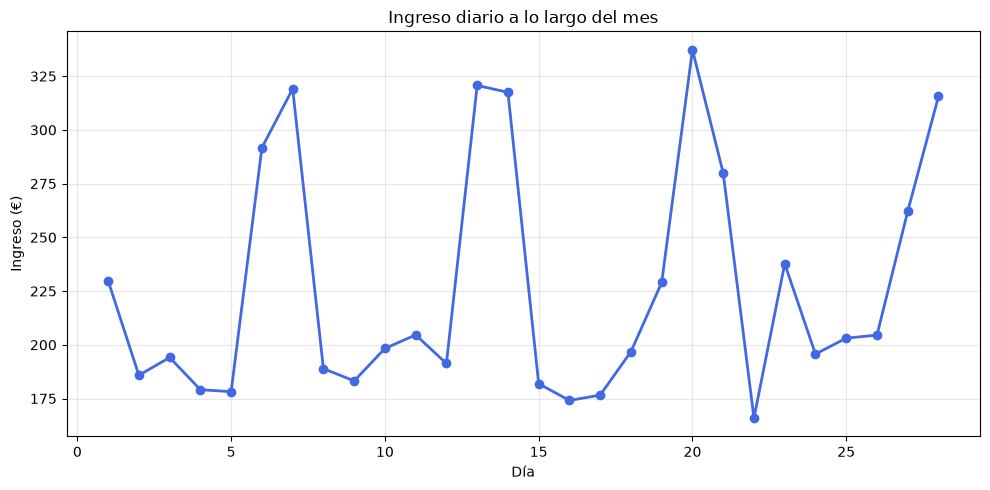

In [21]:
dias = np.arange(1, 29)
plt.figure(figsize=(10, 5))
plt.plot(dias, ingreso_diario, marker="o", color="royalblue", linewidth=2)
plt.title("Ingreso diario a lo largo del mes")
plt.xlabel("Día")
plt.ylabel("Ingreso (€)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Ejercicio 16.** Quiero comparar cuánto dinero generó cada producto en el mes.

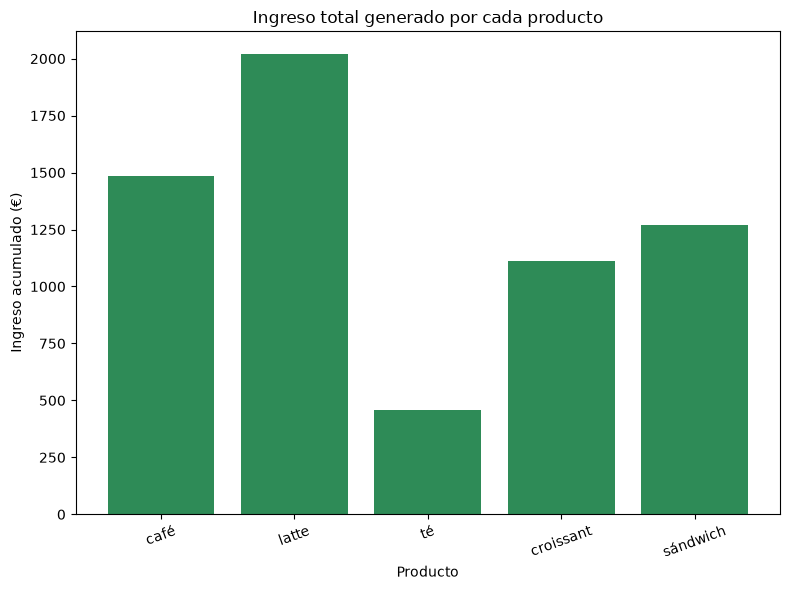

In [22]:
ingreso_por_producto = ventas * precios
ingreso_total_producto = ingreso_por_producto.sum(axis=0)

plt.figure(figsize=(8, 6))
plt.bar(productos, ingreso_total_producto, color="seagreen")
plt.title("Ingreso total generado por cada producto")
plt.xlabel("Producto")
plt.ylabel("Ingreso acumulado (€)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


**Ejercicio 17.** Quiero ver en un mismo gráfico las unidades vendidas cada día de los 5 productos, una línea por producto.

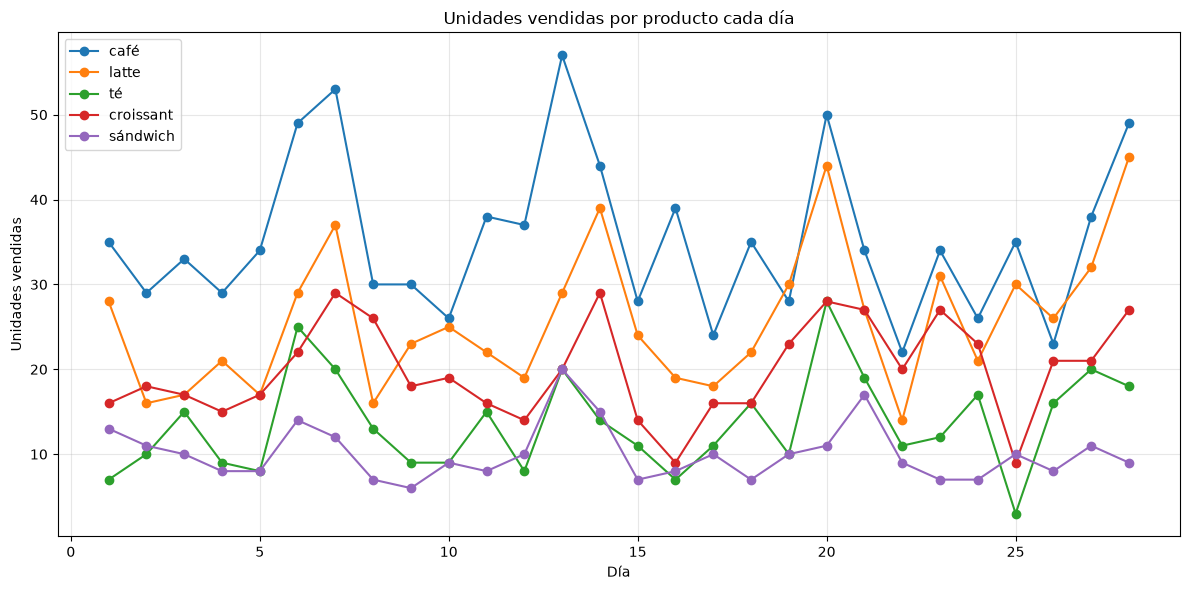

In [23]:
plt.figure(figsize=(12, 6))
for i, producto in enumerate(productos):
    plt.plot(np.arange(1, 29), ventas[:, i], marker="o", label=producto)
plt.title("Unidades vendidas por producto cada día")
plt.xlabel("Día")
plt.ylabel("Unidades vendidas")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Ejercicio 18.** Quiero ver la matriz de ventas (días × productos) como un mapa de calor.

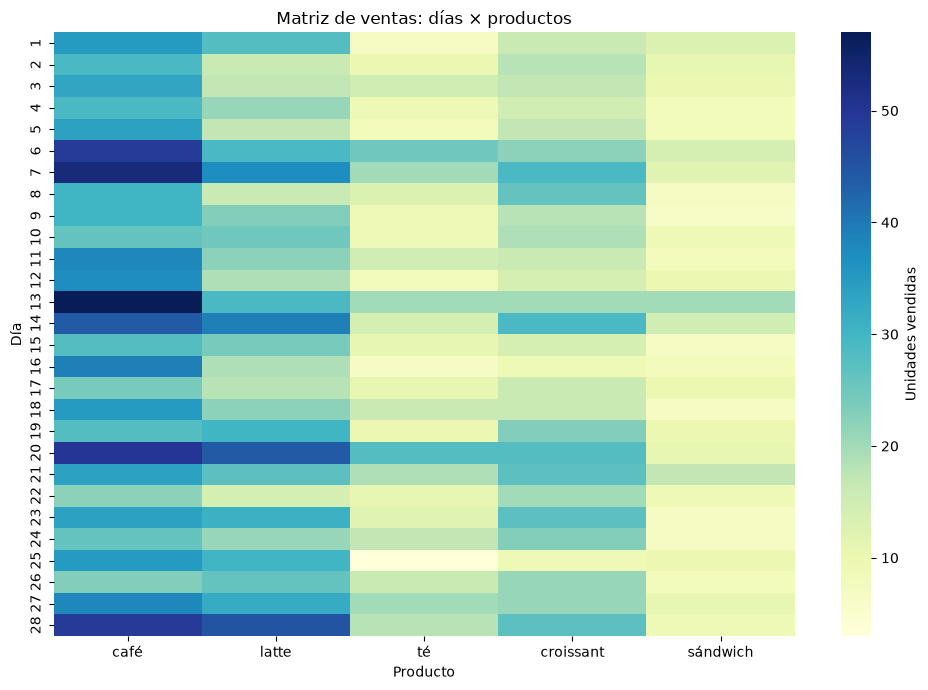

In [24]:
plt.figure(figsize=(10, 7))
sns.heatmap(
    ventas,
    cmap="YlGnBu",
    xticklabels=productos,
    yticklabels=np.arange(1, 29),
    cbar_kws={"label": "Unidades vendidas"},
)
plt.title("Matriz de ventas: días × productos")
plt.xlabel("Producto")
plt.ylabel("Día")
plt.tight_layout()
plt.show()


### Con los datos de las propinas 💵

Usa el DataFrame `propinas` tal como quedó al final de la Parte 2.

**Ejercicio 19.** Quiero ver el histograma del importe de la cuenta.

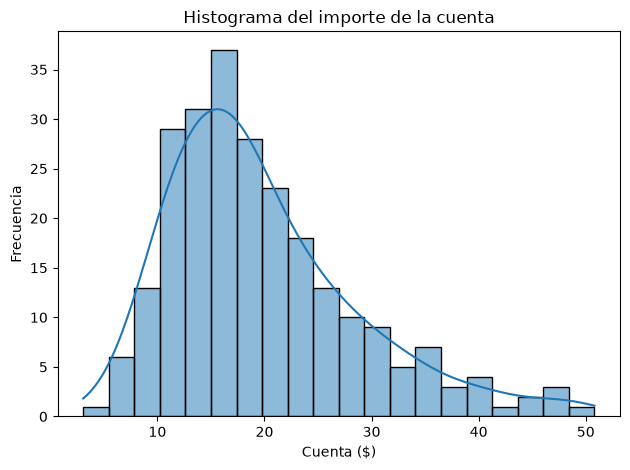

In [25]:
sns.histplot(propinas["cuenta"], bins=20, kde=True)
plt.title("Histograma del importe de la cuenta")
plt.xlabel("Cuenta ($)")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()


**Ejercicio 20.** Quiero visualizar la relación entre la cuenta y la propina.

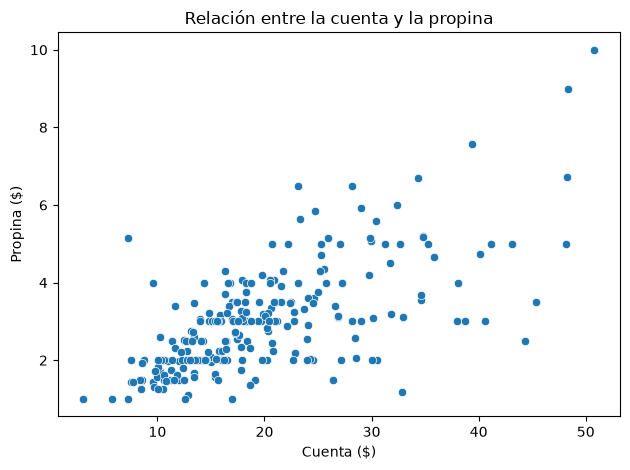

In [26]:
sns.scatterplot(data=propinas, x="cuenta", y="propina")
plt.title("Relación entre la cuenta y la propina")
plt.xlabel("Cuenta ($)")
plt.ylabel("Propina ($)")
plt.tight_layout()
plt.show()


**Ejercicio 21.** Quiero ver esa misma relación, pero distinguiendo las comidas de las cenas.

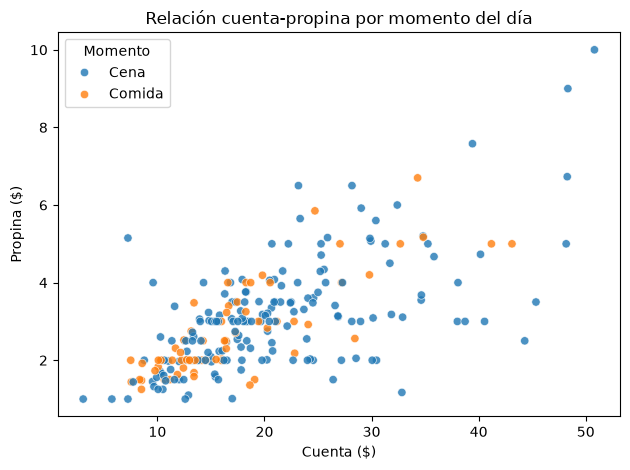

In [27]:
sns.scatterplot(data=propinas, x="cuenta", y="propina", hue="momento", alpha=0.8)
plt.title("Relación cuenta-propina por momento del día")
plt.xlabel("Cuenta ($)")
plt.ylabel("Propina ($)")
plt.legend(title="Momento")
plt.tight_layout()
plt.show()


**Ejercicio 22.** Quiero ver si hay valores atípicos en el porcentaje de propina de cada día de la semana.

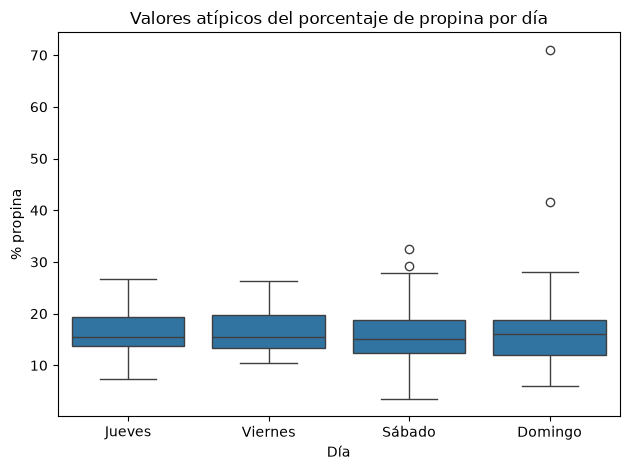

In [28]:
sns.boxplot(data=propinas, x="dia", y="pct_propina", order=["Jueves", "Viernes", "Sábado", "Domingo"])
plt.title("Valores atípicos del porcentaje de propina por día")
plt.xlabel("Día")
plt.ylabel("% propina")
plt.tight_layout()
plt.show()


**Ejercicio 23.** Quiero ver cuántas mesas se atendieron cada día.

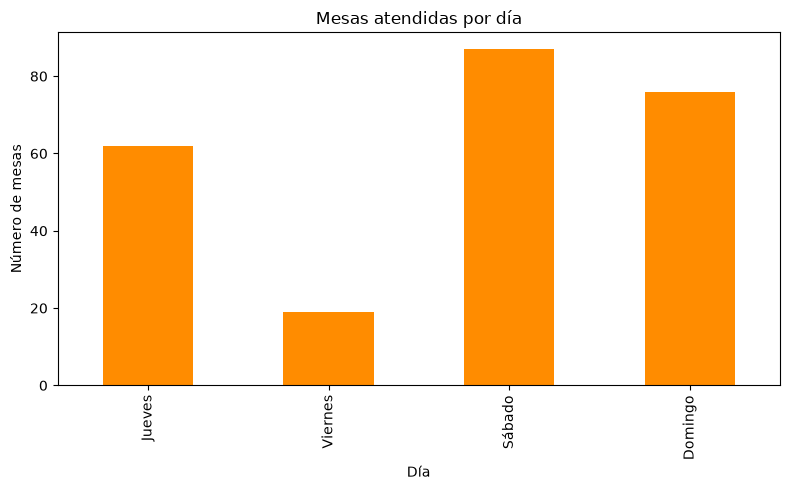

In [29]:
conteo_dias = propinas["dia"].value_counts().reindex(["Jueves", "Viernes", "Sábado", "Domingo"])
plt.figure(figsize=(8, 5))
conteo_dias.plot(kind="bar", color="darkorange")
plt.title("Mesas atendidas por día")
plt.xlabel("Día")
plt.ylabel("Número de mesas")
plt.tight_layout()
plt.show()


**Ejercicio 24.** Quiero comparar la propina media según el número de personas en la mesa, separando mesas de fumadores y de no fumadores.

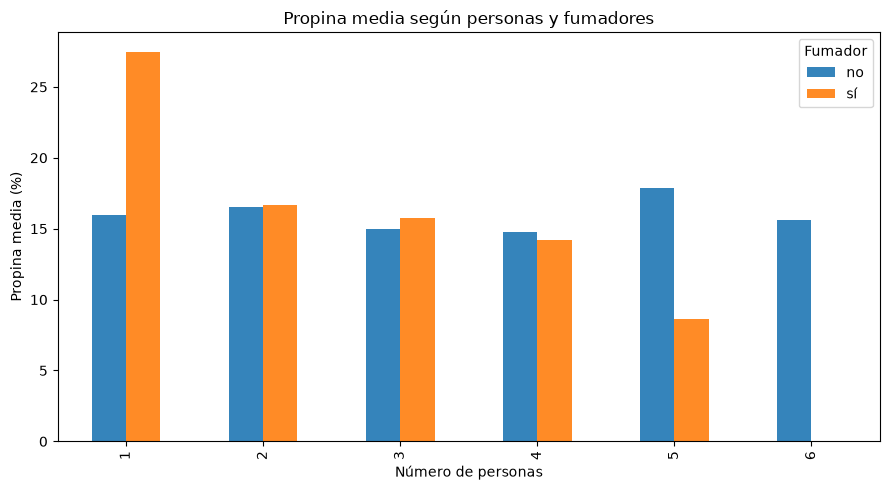

In [30]:
resumen_personas_fumador = propinas.groupby(["personas", "fumador"])["pct_propina"].mean().unstack()
resumen_personas_fumador.plot(kind="bar", figsize=(9, 5), alpha=0.9)
plt.title("Propina media según personas y fumadores")
plt.xlabel("Número de personas")
plt.ylabel("Propina media (%)")
plt.legend(title="Fumador")
plt.tight_layout()
plt.show()


### Con un dataset nuevo: los pingüinos 🐧

El archivo `data/penguins.csv` tiene medidas de 344 pingüinos de tres especies de la Antártida:

| Columna | Significado |
|---|---|
| `species` | especie: `Adelie`, `Chinstrap`, `Gentoo` |
| `island` | isla donde se registró |
| `bill_length_mm` | longitud del pico (mm) |
| `bill_depth_mm` | profundidad (altura) del pico (mm) |
| `flipper_length_mm` | longitud de la aleta (mm) |
| `body_mass_g` | peso (g) |
| `sex` | `Male` / `Female` |

**Ejercicio 25.** Carga los datos en un DataFrame llamado `pinguinos`. Quiero ver el histograma del peso de los pingüinos.

Forma del DataFrame: (344, 7)
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  
2       3250.0  Female  
3          NaN     NaN  
4       3450.0  Female  


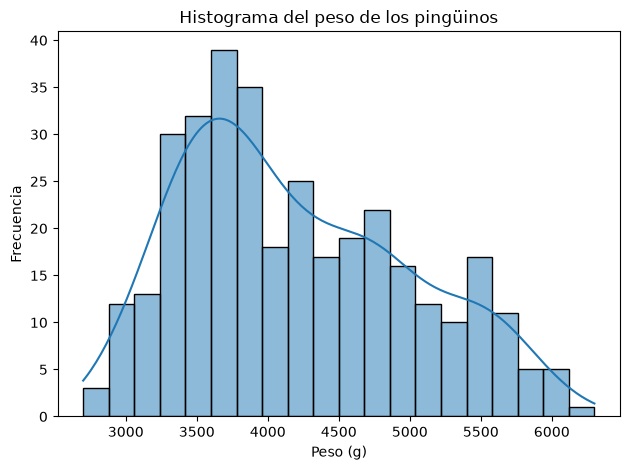

In [31]:
pinguinos = pd.read_csv(DATA_DIR / "penguins.csv")
print("Forma del DataFrame:", pinguinos.shape)
print(pinguinos.head())

sns.histplot(pinguinos["body_mass_g"], bins=20, kde=True)
plt.title("Histograma del peso de los pingüinos")
plt.xlabel("Peso (g)")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()


**Ejercicio 26.** Quiero ver si la distribución del peso cambia según la especie.

/var/folders/69/6gbdnhgx5y3_xnc99kqgpnd00000gp/T/ipykernel_14154/1605101250.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title="Especie")


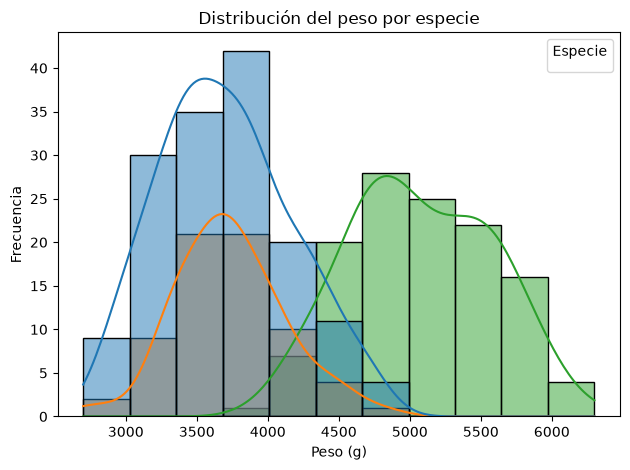

In [32]:
sns.histplot(data=pinguinos, x="body_mass_g", hue="species", kde=True, multiple="layer", alpha=0.5)
plt.title("Distribución del peso por especie")
plt.xlabel("Peso (g)")
plt.ylabel("Frecuencia")
plt.legend(title="Especie")
plt.tight_layout()
plt.show()


**Ejercicio 27.** Quiero ver si hay valores atípicos en la longitud de la aleta de cada especie.

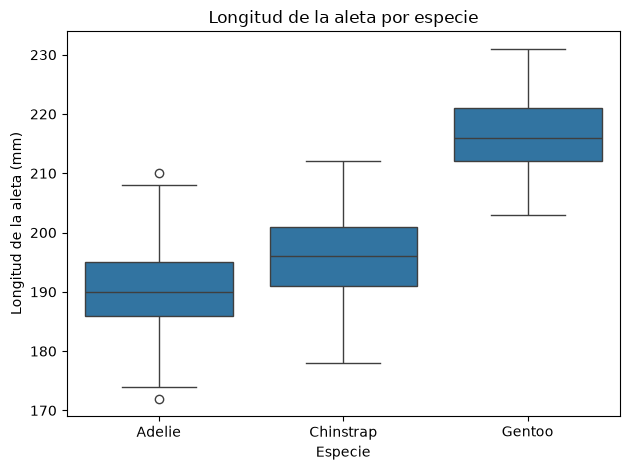

In [33]:
sns.boxplot(data=pinguinos, x="species", y="flipper_length_mm")
plt.title("Longitud de la aleta por especie")
plt.xlabel("Especie")
plt.ylabel("Longitud de la aleta (mm)")
plt.tight_layout()
plt.show()


**Ejercicio 28.** Quiero visualizar la relación entre la longitud y la profundidad del pico, distinguiendo las especies.

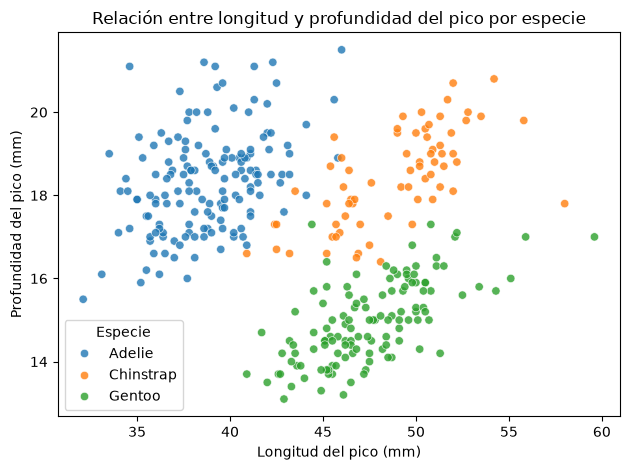

In [34]:
sns.scatterplot(data=pinguinos, x="bill_length_mm", y="bill_depth_mm", hue="species", alpha=0.8)
plt.title("Relación entre longitud y profundidad del pico por especie")
plt.xlabel("Longitud del pico (mm)")
plt.ylabel("Profundidad del pico (mm)")
plt.legend(title="Especie")
plt.tight_layout()
plt.show()


**Ejercicio 29.** Quiero ver en una sola figura el histograma de las cuatro medidas numéricas, cada una en su propio gráfico.

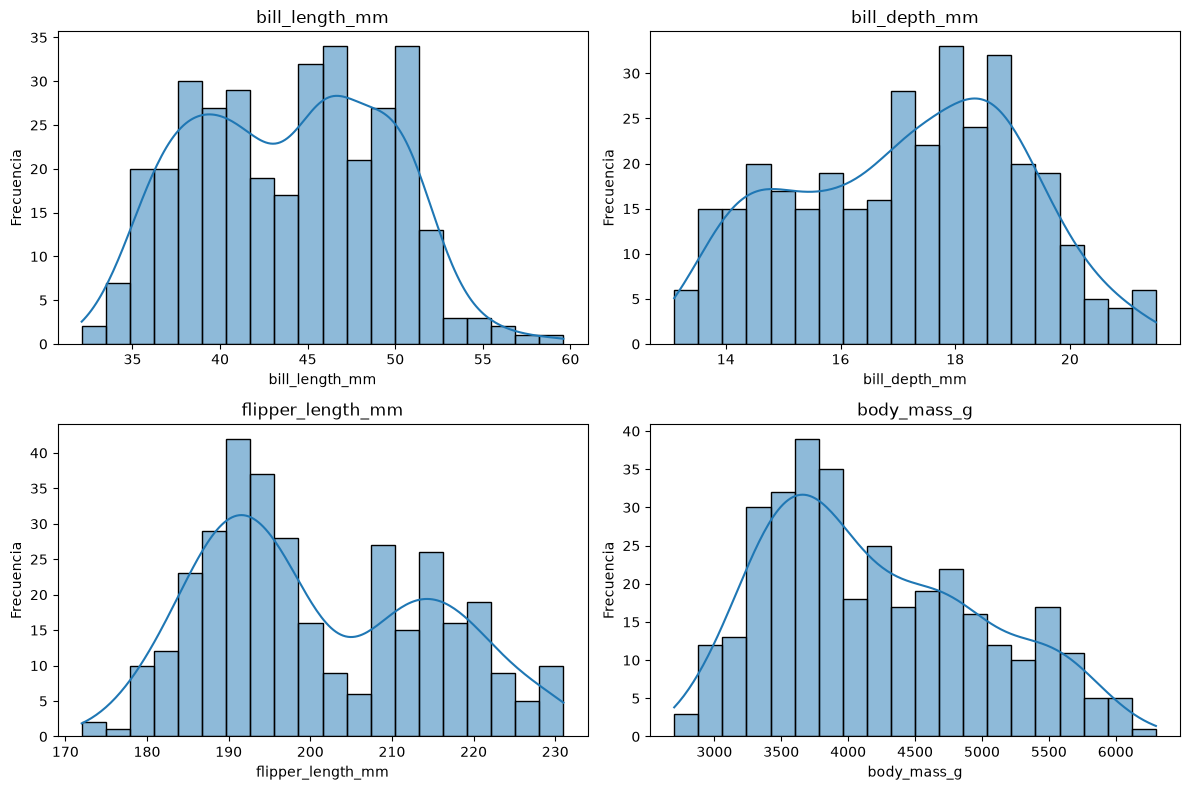

In [35]:
cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, cols):
    sns.histplot(pinguinos[col], bins=20, kde=True, ax=ax)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()


**Ejercicio 30.** Quiero ver qué medidas numéricas están más relacionadas entre sí.

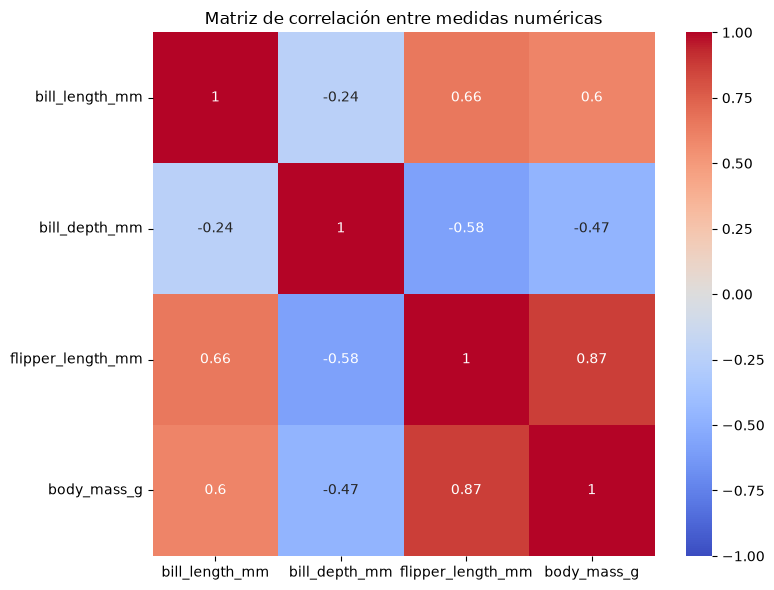

In [36]:
cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
matriz_corr = pinguinos[cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación entre medidas numéricas")
plt.tight_layout()
plt.show()


**Ejercicio 31.** Quiero comparar el peso medio de cada especie, separando machos y hembras.

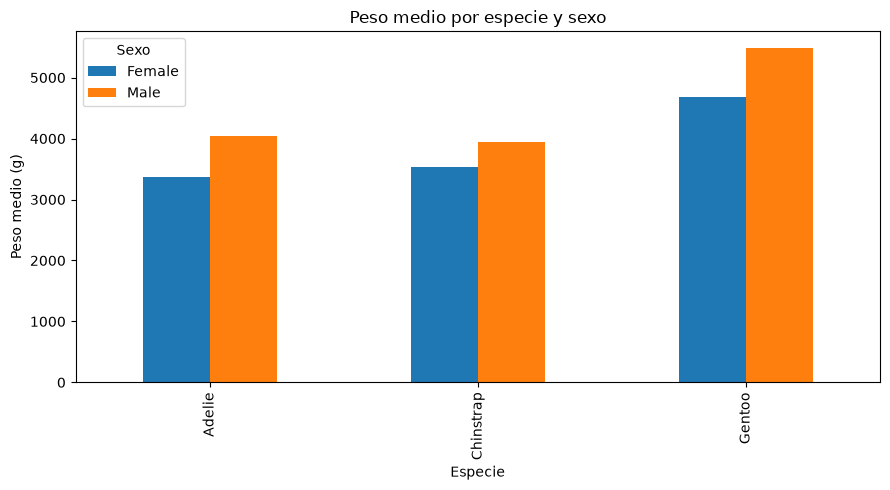

In [37]:
pinguinos_sexo = pinguinos.dropna(subset=["sex"]).copy()
media_peso = pinguinos_sexo.groupby(["species", "sex"])["body_mass_g"].mean().unstack()
media_peso.plot(kind="bar", figsize=(9, 5))
plt.title("Peso medio por especie y sexo")
plt.xlabel("Especie")
plt.ylabel("Peso medio (g)")
plt.legend(title="Sexo")
plt.tight_layout()
plt.show()
